# Data Augmentation: Help the Doctor (Group 51)

| § | Question |
|---|---|
| 1 | Why does this dataset need augmentation? |
| 2 | What do we do? |
| 3 | Does it help, and for which model? |
| 4 | Summary |

In [1]:
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE                 # pip install imbalanced-learn
from imblearn.pipeline import Pipeline                   # like sklearn's Pipeline, but also accepts samplers
from imblearn.under_sampling import RandomUnderSampler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.class_weight import compute_sample_weight

DATA = Path("../../data")                        # clean_train.csv is written by 01_data_analysis.ipynb
FIG = Path("figures"); FIG.mkdir(exist_ok=True)  # figures for the paper (PDF)
TARGET = "medical_specialty"
SEED = 42

df = pd.read_csv(DATA / "clean_train.csv", sep=";", encoding="utf-8-sig", keep_default_na=False)
LABELS = df[TARGET].value_counts().index.tolist()  # largest class first
print(df.shape)

(2662, 5)


## 1. Why augment?

* **Imbalance**: Surgery has 890 records, Dermatology 25 (35.6 : 1, see `01_data_analysis.ipynb`).
* **Every class counts**: the automatic evaluation requires F1 ≥ 0.25 for *every* class, so the 25 Dermatology records matter as much as the 890 Surgery ones. Without balancing, the models only learn the big classes (section 3).

In [2]:
shared = df["transcription"].duplicated(keep=False) & (df["transcription"] != "")
pd.DataFrame({
    "records": df[TARGET].value_counts(),
    "% transcription shared with another record": shared.groupby(df[TARGET]).mean().mul(100).round(0),
}).loc[LABELS]

,records,% transcription shared with another record
medical_specialty,,
Surgery,890,60.0
Cardiovascular-Pulmonary,308,58.0
Orthopedic,300,71.0
Radiology,222,73.0
General Medicine,211,8.0
Gastroenterology,195,58.0
Neurology,184,55.0
Obstetrics-Gynecology,135,62.0
Neurosurgery,78,92.0


**What we see.** Four classes have fewer than 80 records (Neurosurgery, Ophthalmology, Psychiatry-Psychology, Dermatology). Augmentation can give them more examples. It **cannot** fix the last column: 92% of the Neurosurgery records have the same transcription as a record of another class, mostly Surgery or Orthopedic (Obs. 4 of the analysis), so a new version of that text is still ambiguous.

## 2. The augmentation: clinical EDA

Our augmentation, **clinical EDA**, is an adaptation of **EDA** (Wei and Zou, 2019), the usual recipe for text classification. EDA makes a new version of a text with four random operations on *words*. We keep two of them, applied to whole sentences and to medical abbreviations, and leave out the other two:

| EDA operation | clinical EDA | why |
|---|---|---|
| random deletion: delete each word with probability α | **sentence dropout**: delete each *sentence* with p = 0.2 | the kept sentences stay exactly as written, so negations (*no fracture*) and function words (*the, was, then*: the signal of Surgery and Radiology, Obs. 7) are untouched |
| synonym replacement with WordNet | **abbreviation replacement**: *MRI* ↔ *magnetic resonance imaging*, each occurrence with p = 0.5 | WordNet knows little medicine; abbreviations are the synonyms these transcriptions actually use (*MRI* is in 301 of them) |
| random swap: exchange two random words | not used | for TF-IDF a swap changes no word count; it only creates word pairs that never occur in real transcriptions. Protecting words such as *no* does not help: the word next to it can still be swapped away (*no fracture* → *no knee*) |
| random insertion: insert a WordNet synonym at a random position | not used | it needs WordNet, and the inserted word lands in an unrelated sentence |

**Why these values.** With p = 0.2 a new version keeps about 80% of the sentences, so it is still clearly the same report; this is the same order of change as EDA, which modifies α = 10% of the words (the value Wei and Zou call a "sweet spot"). An abbreviation appears only a few times per transcription, so with p = 0.5 each occurrence is as likely to change as to stay, which makes the new versions of a record as different from each other as possible. The values are not tuned: section 3.1 shows that p between 0.1 and 0.5 gives the same results.

**New rows, no new information**: the original records are all kept, and we **add** new rows; each new row is a modified copy of an existing record of the same class, with the same label. For example, a transcription with 12 sentences becomes the same text with, on average, 2–3 sentences missing. In section 3 we also run the original EDA, to check whether these changes matter.

In [3]:
# Where a new sentence starts: after ".", "!" or "?", then "," or spaces, then a capital letter or a digit.
# The text is cut *at* that point, so joining the pieces gives back exactly the same text (".," included).
SENTENCE_BOUNDARY = re.compile(r"(?<=[.!?])(?=[,\s]+[A-Z0-9])")

def sentence_dropout(text, rng, p=0.2):
    sentences = SENTENCE_BOUNDARY.split(text)
    if len(sentences) < 3:                      # too short to remove anything
        return text
    kept = [s for s in sentences if rng.random() > p]
    return "".join(kept or sentences).lstrip(", ")


# Abbreviations that are frequent in the transcriptions and have one clear meaning
ABBREVIATIONS = {
    "MRI": "magnetic resonance imaging", "CT": "computed tomography", "EKG": "electrocardiogram",
    "ECG": "electrocardiogram", "EEG": "electroencephalogram", "EMG": "electromyography",
    "IV": "intravenous", "CBC": "complete blood count", "PACU": "post-anesthesia care unit",
    "ICU": "intensive care unit", "GI": "gastrointestinal", "MI": "myocardial infarction",
    "BP": "blood pressure", "HR": "heart rate", "CVA": "cerebrovascular accident",
    "DVT": "deep vein thrombosis", "COPD": "chronic obstructive pulmonary disease",
    "HTN": "hypertension", "EGD": "esophagogastroduodenoscopy", "CAD": "coronary artery disease",
    "TIA": "transient ischemic attack", "LMA": "laryngeal mask airway",
    "ACL": "anterior cruciate ligament", "EBL": "estimated blood loss",
    "GERD": "gastroesophageal reflux disease", "UTI": "urinary tract infection",
    "CABG": "coronary artery bypass graft", "CHF": "congestive heart failure",
    "DM": "diabetes mellitus", "SOB": "shortness of breath",
}
EXPANSIONS = {}
for short_form, long_form in ABBREVIATIONS.items():
    EXPANSIONS.setdefault(long_form, short_form)   # electrocardiogram -> EKG
ABBREVIATION = re.compile(r"\b(?:" + "|".join(ABBREVIATIONS) + r")\b"            # MRI (exact case)
                          r"|(?i:\b(?:" + "|".join(EXPANSIONS) + r")\b)")        # magnetic resonance imaging (any case)

def replace_abbreviations(text, rng, p=0.5):
    def replace(match):
        word = match.group()
        if rng.random() > p:
            return word
        return ABBREVIATIONS.get(word) or EXPANSIONS[word.lower()]
    return ABBREVIATION.sub(replace, text)


def clinical_eda_copy(row, rng, p_sentence=0.2, p_abbreviation=0.5):
    # A new version of a training record: same label, same keywords and sample name
    row = row.copy()
    row["transcription"] = sentence_dropout(row["transcription"], rng, p_sentence)
    row["description"] = replace_abbreviations(row["description"], rng, p_abbreviation)
    row["transcription"] = replace_abbreviations(row["transcription"], rng, p_abbreviation)
    return row

One example: a short Neurology transcription with *MRI* (first 600 characters).

In [4]:
mri = df[(df[TARGET] == "Neurology") & df["transcription"].str.contains(r"\bMRI\b")]
row = mri.loc[mri["transcription"].str.len().idxmin()]
new = clinical_eda_copy(row, random.Random(SEED))

print("ORIGINAL :", row["transcription"][:600], "\n")
print("CLINICAL EDA:", new["transcription"][:600], "\n")
n_before, n_after = len(SENTENCE_BOUNDARY.split(row["transcription"])), len(SENTENCE_BOUNDARY.split(new["transcription"]))
print(f"{n_before} sentences -> {n_after} sentences ({n_before - n_after} removed by sentence dropout)")

ORIGINAL : EXAM: MRI of the brain without contrast.,HISTORY: Daily headaches for 6 months in a 57-year-old.,TECHNIQUE:Noncontrast axial and sagittal images were acquired through the brain in varying degrees of fat and water weighting.,FINDINGS: The brain is normal in signal intensity and morphology for age.  There are no extraaxial fluid collections.  There is no hydrocephalus/midline shift.  Posterior fossa, 7th and 8th nerve complexes and intraorbital contents are within normal limits.  The normal vascular flow volumes are maintained.  The paranasal sinuses are clear.,Diffusion images demonstrate no ar 

CLINICAL EDA: EXAM: magnetic resonance imaging of the brain without contrast.,TECHNIQUE:Noncontrast axial and sagittal images were acquired through the brain in varying degrees of fat and water weighting.,FINDINGS: The brain is normal in signal intensity and morphology for age.  There are no extraaxial fluid collections.  There is no hydrocephalus/midline shift.  Posterior fossa, 7th

### 2.1 Filling up the small classes

In the training part, every class gets new rows until it is as large as the largest class (Surgery). Each new row is a new version of a random record of the same class.

To know whether clinical EDA is worth it, section 3 compares it with other ways of dealing with the imbalance:

| method | what it does |
|---|---|
| random oversampling | the new rows are exact copies |
| original EDA | the new rows get random deletion and random swap of α = 10% of their words; synonym replacement and random insertion are left out because both need WordNet |
| SMOTE (Chawla et al., 2002) | each new row is a point between a record and one of its 5 nearest neighbours of the same class, in TF-IDF space: a vector, not a text |
| random undersampling | removes records of the big classes until every class is as small as the smallest one (20 records) |
| class weights | no new rows: during training, the error on each record is multiplied by n / (12 · n<sub>class</sub>), so a mistake on a Dermatology record (20 in the training part) costs 35× more than one on a Surgery record (712). LR: `class_weight="balanced"`; NB: the same weights passed as `sample_weight` |

In [5]:
def fields(d):
    # the input of the models: the four text fields in one string
    return d["description"] + " " + d["sample_name"] + " " + d["transcription"] + " " + d["keywords"]

def exact_copy(row, rng):
    return row

def eda(text, rng, alpha=0.1):
    # original EDA without WordNet: random deletion + random swap
    words = text.split()
    if len(words) < 4:
        return text
    words = [w for w in words if rng.random() > alpha] or words   # random deletion
    for _ in range(int(alpha * len(words))):                        # random swap
        i, j = rng.randrange(len(words)), rng.randrange(len(words))
        words[i], words[j] = words[j], words[i]
    return " ".join(words)

def original_eda_copy(row, rng):
    row = row.copy()
    row["description"] = eda(row["description"], rng)
    row["transcription"] = eda(row["transcription"], rng)
    return row

def oversample(train_part, make_copy, seed=SEED):
    # Add new rows to every class until it has as many rows as the largest class
    rng = random.Random(seed)
    target = train_part[TARGET].value_counts().max()
    new_rows = []
    for label, group in train_part.groupby(TARGET):
        for _ in range(target - len(group)):
            new_rows.append(make_copy(group.iloc[rng.randrange(len(group))], rng))
    return pd.concat([train_part, pd.DataFrame(new_rows)], ignore_index=True)

In [6]:
train_idx, valid_idx = train_test_split(df.index, test_size=0.2, random_state=SEED, stratify=df[TARGET])
train_part = df.loc[train_idx]
augmented = oversample(train_part, clinical_eda_copy)

# How different is a new row from its original? Cosine similarity of the TF-IDF vectors (100% = identical)
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000)
vectors = tfidf.fit(fields(train_part)).transform
sample = train_part[train_part["transcription"] != ""].sample(300, random_state=SEED)
for name, make_copy in [("clinical EDA", clinical_eda_copy), ("original EDA", original_eda_copy)]:
    rng = random.Random(SEED)
    new_rows = pd.DataFrame([make_copy(row, rng) for _, row in sample.iterrows()])
    print(f"{name}: a new row is {cosine_similarity(vectors(fields(sample)), vectors(fields(new_rows))).diagonal().mean():.0%} similar to its original")
similarity = cosine_similarity(vectors(fields(sample)))
labels = sample[TARGET].to_numpy(dtype=object)
same_class = (labels[:, None] == labels) & (similarity < 0.999)                  # skip identical texts
print(f"two different records of the same class: {similarity[np.triu(same_class, 1)].mean():.0%} similar\n")

pd.DataFrame({"training part": train_part[TARGET].value_counts(),
              "after clinical EDA": augmented[TARGET].value_counts()}).loc[LABELS]

clinical EDA: a new row is 94% similar to its original


original EDA: a new row is 86% similar to its original


two different records of the same class: 5% similar



,training part,after clinical EDA
medical_specialty,,
Surgery,712,712
Cardiovascular-Pulmonary,246,712
Orthopedic,240,712
Radiology,178,712
General Medicine,169,712
Gastroenterology,156,712
Neurology,147,712
Obstetrics-Gynecology,108,712
Neurosurgery,62,712


## 3. Does it help?

The models are copied from `TF-IDF_Linear-SVM.ipynb`: the four fields concatenated, TF-IDF of 1- and 2-grams (lowercase, `min_df=2`, `sublinear_tf`, 50k features), then
* **Multinomial NB** (default settings), the model of the baseline;
* **Logistic Regression** (`C=1`, `max_iter=2000`, `random_state=42`). In that notebook it uses `class_weight="balanced"`: this is our row *class weights*. The row *none* is the same model without class weights.

Each setting is trained on **3 random 80/20 stratified splits** (seeds 42, 1, 2), and we report mean ± standard deviation of:
* accuracy and macro-F1 on the validation part;
* the **lowest per-class F1** (the automatic evaluation requires every class ≥ 0.25);
* macro-F1 when the keywords of the validation records are removed (how much the model relies on them).

⏱ About 10 minutes in total (this section and section 3.1).

In [7]:
def tfidf_model(classifier, sampler=None):
    tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50_000)
    sampler_step = [("sampler", sampler)] if sampler is not None else []   # SMOTE / undersampling act on the vectors
    return Pipeline([("tfidf", tfidf), *sampler_step, ("classifier", classifier)])

def evaluate(model, valid):
    pred = model.predict(fields(valid))
    pred_no_kw = model.predict(fields(valid.assign(keywords="")))  # same records, keywords removed
    f1 = f1_score(valid[TARGET], pred, labels=LABELS, average=None, zero_division=0)
    f1_no_kw = f1_score(valid[TARGET], pred_no_kw, labels=LABELS, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(valid[TARGET], pred), "macro-F1": f1.mean(), "min class F1": f1.min(),
            "macro-F1 (no keywords)": f1_no_kw, **dict(zip(LABELS, f1))}

NEW_ROWS = {"none": None, "random oversampling": exact_copy, "original EDA": original_eda_copy,
            "clinical EDA": clinical_eda_copy}
SAMPLERS = {"SMOTE": SMOTE, "random undersampling": RandomUnderSampler}
MODELS = {"Multinomial NB": lambda: MultinomialNB(),
          "Logistic Regression": lambda: LogisticRegression(C=1.0, max_iter=2000, random_state=42)}
SEEDS = [42, 1, 2]

rows = []
for seed in SEEDS:
    train_idx, valid_idx = train_test_split(df.index, test_size=0.2, random_state=seed, stratify=df[TARGET])
    train_part, valid = df.loc[train_idx], df.loc[valid_idx]
    datasets = {name: train_part if make_copy is None else oversample(train_part, make_copy, seed)
                for name, make_copy in NEW_ROWS.items()}

    for model_name, classifier in MODELS.items():
        for name, data in datasets.items():                      # new rows made from the text
            model = tfidf_model(classifier()).fit(fields(data), data[TARGET])
            rows.append({"model": model_name, "balancing": name, "seed": seed, **evaluate(model, valid)})
        for name, sampler in SAMPLERS.items():                   # new / removed rows in TF-IDF space
            model = tfidf_model(classifier(), sampler(random_state=seed))
            model.fit(fields(train_part), train_part[TARGET])
            rows.append({"model": model_name, "balancing": name, "seed": seed, **evaluate(model, valid)})

    # No new rows: the error on each record is weighted by n / (12 * n_class)
    weights = compute_sample_weight("balanced", train_part[TARGET])
    model = tfidf_model(MultinomialNB())
    model.fit(fields(train_part), train_part[TARGET], classifier__sample_weight=weights)
    rows.append({"model": "Multinomial NB", "balancing": "class weights", "seed": seed, **evaluate(model, valid)})
    model = tfidf_model(LogisticRegression(C=1.0, max_iter=2000, random_state=42, class_weight="balanced"))
    model.fit(fields(train_part), train_part[TARGET])
    rows.append({"model": "Logistic Regression", "balancing": "class weights", "seed": seed, **evaluate(model, valid)})
    print(f"split {seed} done")

results = pd.DataFrame(rows)

split 42 done


split 1 done


split 2 done


In [8]:
METRICS = ["accuracy", "macro-F1", "min class F1", "macro-F1 (no keywords)"]
BALANCING = [*NEW_ROWS, *SAMPLERS, "class weights"]
ORDER = [(model, b) for model in MODELS for b in BALANCING]

def mean_std(table, group):
    mean, std = table.groupby(group, sort=False)[METRICS].mean(), table.groupby(group, sort=False)[METRICS].std()
    return mean.map("{:.3f}".format) + " ± " + std.map("{:.3f}".format)

mean_std(results, ["model", "balancing"]).loc[ORDER]

accuracy       macro-F1  \
model               balancing                                            
Multinomial NB      none                  0.442 ± 0.004  0.161 ± 0.003   
                    random oversampling   0.487 ± 0.011  0.509 ± 0.023   
                    original EDA          0.488 ± 0.017  0.513 ± 0.009   
                    clinical EDA          0.490 ± 0.012  0.516 ± 0.021   
                    SMOTE                 0.473 ± 0.011  0.491 ± 0.008   
                    random undersampling  0.424 ± 0.031  0.436 ± 0.030   
                    class weights         0.458 ± 0.011  0.466 ± 0.010   
Logistic Regression none                  0.462 ± 0.016  0.280 ± 0.028   
                    random oversampling   0.523 ± 0.017  0.546 ± 0.007   
                    original EDA          0.502 ± 0.025  0.524 ± 0.018   
                    clinical EDA          0.513 ± 0.013  0.533 ± 0.003   
                    SMOTE                 0.503 ± 0.023  0.534 ± 0.026   
                    random undersampling  0.475 ± 0.010  0.490 ± 0.018   
                    class weights         0.532 ± 0.017  0.570 ± 0.015   

                                           min class F1 macro-F1 (no keywords)  
model               balancing                                                   
Multinomial NB      none                  0.000 ± 0.000          0.160 ± 0.005  
                    random oversampling   0.257 ± 0.059          0.504 ± 0.037  
                    original EDA          0.278 ± 0.011          0.512 ± 0.017  
                    clinical EDA          0.274 ± 0.036          0.507 ± 0.038  
                    SMOTE                 0.271 ± 0.043          0.499 ± 0.007  
                    random undersampling  0.257 ± 0.087          0.429 ± 0.038  
                    class weights         0.271 ± 0.027          0.479 ± 0.012  
Logistic Regression none                  0.000 ± 0.000          0.229 ± 0.016  
                    random oversampling   0.243 ± 0.060          0.473 ± 0.010  
                    original EDA          0.188 ± 0.047          0.444 ± 0.013  
                    clinical EDA          0.242 ± 0.086          0.467 ± 0.019  
                    SMOTE                 0.201 ± 0.095          0.463 ± 0.013  
                    random undersampling  0.319 ± 0.058          0.469 ± 0.033  
                    class weights         0.324 ± 0.035          0.525 ± 0.023

**Same numbers as `TF-IDF_Linear-SVM.ipynb`.** The table above is the **mean of the 3 splits** (for LR with class weights: 0.532 accuracy). That notebook uses **only split 42**, so to compare we take split 42 alone. Its two models are our *Multinomial NB, none* and *Logistic Regression, class weights* (it uses `class_weight="balanced"` for LR and SVM, nothing for NB). There, on split 42: NB 0.441 accuracy / 0.163 macro-F1 with 6 classes at F1 = 0; LR 0.508 / 0.553 with lowest class F1 0.33 (Radiology) and no class at 0. Here, on the same split:

In [9]:
split42 = results[results["seed"] == 42].set_index(["model", "balancing"])
split42 = split42.loc[[("Multinomial NB", "none"), ("Logistic Regression", "class weights")]]
split42.assign(**{"lowest class": split42[LABELS].idxmin(axis=1), "classes at F1 = 0": (split42[LABELS] == 0).sum(axis=1)}
               )[["accuracy", "macro-F1", "min class F1", "lowest class", "classes at F1 = 0"]].round(3)

,,accuracy,macro-F1,min class F1,lowest class,classes at F1 = 0
model,balancing,,,,,
Multinomial NB,none,0.439,0.160,0.000,Orthopedic,7
Logistic Regression,class weights,0.512,0.555,0.329,Radiology,0


They match up to one or two records (probably a library-version difference). The rows with a lowest class F1 of 0 in the big table are the models **without** balancing, which `TF-IDF_Linear-SVM.ipynb` only runs for NB.

**What we see.** 1. **Balancing is what matters.** Without it some classes are never predicted (lowest class F1 = 0). With balancing, NB goes from 0.16 to 0.44–0.52 macro-F1 and LR from 0.28 to 0.49–0.57.
2. **Changing the text of the new rows adds nothing.** For NB, exact copies, original EDA, SMOTE and clinical EDA all give 0.49–0.52 macro-F1, within one standard deviation. Section 2.1 shows why: for TF-IDF, a clinical EDA row is 94% the same vector as its original (two different records of the same class: 5%), so it works almost like a copy. Original EDA changes more (86%) but in the wrong way: its swaps create word pairs that never occur in real transcriptions, and it is the worst option for LR (lowest class F1 0.19).
3. **Removing data is worse.** Random undersampling keeps 20 records per class (240 of 2,129): NB 0.44, LR 0.49.
4. **Why class weights win for LR but lose for NB.** Copying each Dermatology row 35 times and making each Dermatology row weigh 35 times more than a Surgery row give the same balance; each model has one side effect that breaks this, checked in section 3.1:
   * *LR* learns one weight per word and class, with a penalty (`C`) that keeps the weights small. Oversampling gives it 4× more rows with the same penalty, so the penalty counts less and the model fits the 20 Dermatology records, repeated 35 times, too closely (Dermatology F1 0.56 with clinical EDA, 0.71 with class weights). Class weights keep the 2,129 original rows and the same penalty.
   * *NB* can only use the words of the TF-IDF vocabulary, the 50,000 most frequent words and word pairs of the training rows. With class weights that list is filled by the big classes; with oversampling, the words of the small classes become frequent enough to get in (macro-F1 0.52 vs. 0.47).
5. **The keywords are barely used.** Removing them from the validation records costs LR (class weights) only 0.570 → 0.525 macro-F1, although the first keyword is the label of every training record that has keywords (Obs. 5 of the analysis). In the bag of words, the label word is one token among hundreds (and *surgery* also appears in many transcriptions). Using the first keyword directly is a point for the Models section.

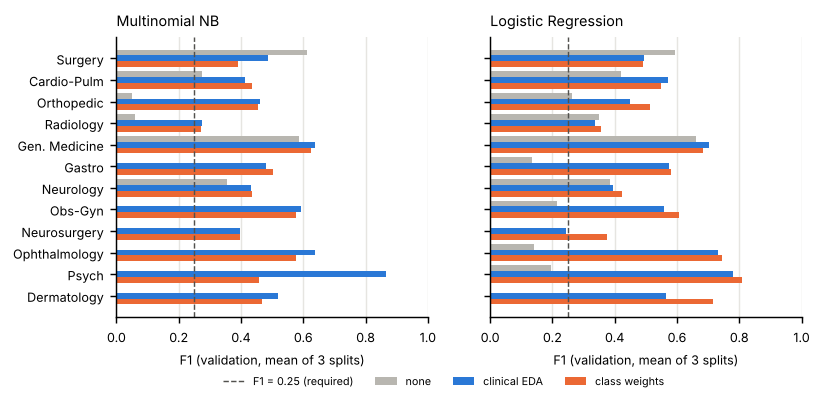

Surgery  Cardiovascular-Pulmonary  \
model               balancing                                          
Multinomial NB      none              0.61                      0.27   
                    clinical EDA      0.49                      0.41   
                    class weights     0.39                      0.43   
Logistic Regression none              0.59                      0.42   
                    clinical EDA      0.49                      0.57   
                    class weights     0.49                      0.55   

                                   Orthopedic  Radiology  General Medicine  \
model               balancing                                                
Multinomial NB      none                 0.05       0.06              0.59   
                    clinical EDA         0.46       0.27              0.64   
                    class weights        0.45       0.27              0.63   
Logistic Regression none                 0.26       0.35              0.66   
                    clinical EDA         0.45       0.34              0.70   
                    class weights        0.51       0.36              0.68   

                                   Gastroenterology  Neurology  \
model               balancing                                    
Multinomial NB      none                       0.00       0.36   
                    clinical EDA               0.48       0.43   
                    class weights              0.50       0.44   
Logistic Regression none                       0.13       0.38   
                    clinical EDA               0.57       0.40   
                    class weights              0.58       0.42   

                                   Obstetrics-Gynecology  Neurosurgery  \
model               balancing                                            
Multinomial NB      none                            0.00          0.00   
                    clinical EDA                    0.59          0.40   
                    class weights                   0.58          0.40   
Logistic Regression none                            0.21          0.00   
                    clinical EDA                    0.56          0.24   
                    class weights                   0.61          0.37   

                                   Ophthalmology  Psychiatry-Psychology  \
model               balancing                                             
Multinomial NB      none                    0.00                   0.00   
                    clinical EDA            0.64                   0.86   
                    class weights           0.58                   0.46   
Logistic Regression none                    0.14                   0.20   
                    clinical EDA            0.73                   0.78   
                    class weights           0.74                   0.81   

                                   Dermatology  
model               balancing                   
Multinomial NB      none                  0.00  
                    clinical EDA          0.52  
                    class weights         0.47  
Logistic Regression none                  0.00  
                    clinical EDA          0.56  
                    class weights         0.71

In [10]:
# Per-class F1 (mean of the 3 splits), for both models
SHORT = {"Cardiovascular-Pulmonary": "Cardio-Pulm", "General Medicine": "Gen. Medicine",
         "Gastroenterology": "Gastro", "Obstetrics-Gynecology": "Obs-Gyn",
         "Psychiatry-Psychology": "Psych"}
BARS = {"none": "#b8b6b0", "clinical EDA": "#2a78d6", "class weights": "#eb6834"}   # grey, blue, orange
INK = "#52514e"
plt.rcParams.update({"figure.dpi": 130, "savefig.bbox": "tight", "font.size": 7,
                     "axes.titlesize": 8, "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True})

per_class = results.groupby(["model", "balancing"])[LABELS].mean()

fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.8), sharey=True)
y = np.arange(len(LABELS))
for ax, model_name in zip(axes, MODELS):
    for k, (balancing, color) in enumerate(BARS.items()):
        ax.barh(y + (k - 1) * 0.27, per_class.loc[(model_name, balancing)], height=0.27, color=color, label=balancing)
    ax.axvline(0.25, color=INK, linestyle="--", linewidth=0.8, label="F1 = 0.25 (required)")
    ax.set(xlim=(0, 1), xlabel="F1 (validation, mean of 3 splits)", title=model_name)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [SHORT.get(label, label) for label in LABELS])
axes[0].invert_yaxis()
axes[0].legend(loc="upper center", bbox_to_anchor=(1.05, -0.17), ncol=4, fontsize=6, frameon=False)
fig.savefig(FIG / "augmentation_f1_per_class.pdf")
plt.show()

per_class.loc[[(m, b) for m in MODELS for b in BARS]].round(2)

**What we see.** Without balancing (grey), NB never predicts six classes (F1 = 0) and LR never predicts two (Neurosurgery, Dermatology). Both clinical EDA and class weights bring every class above the 0.25 line (mean of the 3 splits), except Neurosurgery with LR and clinical EDA (0.24). The small classes gain the most (NB, Psychiatry-Psychology: 0 → 0.86; LR, Ophthalmology: 0.14 → 0.73), and Surgery loses (NB: 0.61 → 0.49) because fewer records are now assigned to it. Per class, the two methods mostly agree; the largest differences are in the smallest classes: with NB, clinical EDA is much better on Psychiatry-Psychology (0.86 vs. 0.46); with LR, class weights are better on Dermatology (0.71 vs. 0.56) and Neurosurgery (0.37 vs. 0.24). The weakest classes remain Radiology and Neurosurgery, the two whose transcriptions are most often shared with another class (73% and 92%, section 1): balancing gives them more weight, it does not remove this ambiguity.

### 3.1 Checking the explanations

Three checks of what we said above, on the same 3 splits (A and B test point 4, C tests the values of section 2):
* **A.** LR with exact copies, but with `C` scaled down by 2,129 / 8,544 ≈ 0.25, so the penalty weighs as much as with the original rows.
* **B.** NB with class weights, but with the TF-IDF vocabulary (the 50,000 words and word pairs) chosen on the oversampled rows.
* **C.** NB with clinical EDA and other values of p for sentence dropout (0.2 is in the table above).

In [11]:
checks = []
for seed in SEEDS:
    train_idx, valid_idx = train_test_split(df.index, test_size=0.2, random_state=seed, stratify=df[TARGET])
    train_part, valid = df.loc[train_idx], df.loc[valid_idx]
    copies = oversample(train_part, exact_copy, seed)

    # A. weaker penalty explains the gap for LR?
    C = len(train_part) / len(copies)
    model = tfidf_model(LogisticRegression(C=C, max_iter=2000, random_state=42)).fit(fields(copies), copies[TARGET])
    checks.append({"check": f"A. LR, random oversampling, C = {C:.2f}", **evaluate(model, valid)})

    # B. vocabulary explains the gap for NB?
    vocabulary = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000).fit(fields(copies)).vocabulary_
    model = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, vocabulary=vocabulary)),
                      ("classifier", MultinomialNB())])
    model.fit(fields(train_part), train_part[TARGET],
              classifier__sample_weight=compute_sample_weight("balanced", train_part[TARGET]))
    checks.append({"check": "B. NB, class weights, vocabulary of the oversampled rows", **evaluate(model, valid)})

    # C. does the value of p matter?
    for p in [0.1, 0.5]:
        data = oversample(train_part, lambda row, rng: clinical_eda_copy(row, rng, p_sentence=p), seed)
        model = tfidf_model(MultinomialNB()).fit(fields(data), data[TARGET])
        checks.append({"check": f"C. NB, clinical EDA, p = {p}", **evaluate(model, valid)})

mean_std(pd.DataFrame(checks), "check")

,accuracy,macro-F1,min class F1,macro-F1 (no keywords)
check,,,,
"A. LR, random oversampling, C = 0.25",0.541 ± 0.017,0.568 ± 0.015,0.319 ± 0.066,0.528 ± 0.021
"B. NB, class weights, vocabulary of the oversampled rows",0.488 ± 0.015,0.514 ± 0.019,0.261 ± 0.038,0.510 ± 0.023
"C. NB, clinical EDA, p = 0.1",0.485 ± 0.019,0.509 ± 0.019,0.244 ± 0.047,0.503 ± 0.035
"C. NB, clinical EDA, p = 0.5",0.481 ± 0.014,0.501 ± 0.012,0.257 ± 0.020,0.504 ± 0.009


**What we see.** * **A confirms the explanation for LR.** With `C` = 0.25, exact copies reach the scores of class weights (macro-F1 0.568 vs. 0.570, lowest class F1 0.319 vs. 0.324). Copying rows and weighting them are equivalent once the penalty is adjusted: the gap in the table came only from `C`. It also shows that `C` has a real effect, so it should be tuned in the Models section.
* **B confirms the explanation for NB.** With the vocabulary of the oversampled rows, class weights reach the scores of the copies (macro-F1 0.514 vs. 0.509, instead of 0.466). For NB the gap came only from which words enter TF-IDF.
* **C: the value of p does not matter.** p = 0.1, 0.2 and 0.5 give 0.509, 0.516 and 0.501 macro-F1, within one standard deviation of each other.

## 4. Summary

**Strategy** (draft for `\subsection{Data Augmentation}`):

> The training data is imbalanced: Surgery has 890 records and Dermatology 25. After splitting, we fill up every class of the training part to the size of the largest class (712 records) by adding new versions of random records of the same class. The new versions are produced by *clinical EDA*, an adaptation of EDA (Wei and Zou, 2019) to clinical transcriptions: (i) *sentence dropout* removes each sentence with probability 0.2 instead of single words, so negations and function words inside the kept sentences are not altered; (ii) *abbreviation replacement* replaces 30 frequent clinical abbreviations by their expansion and vice versa (e.g. MRI ↔ magnetic resonance imaging), each occurrence with probability 0.5, instead of WordNet synonyms. EDA's random swap is not used (it changes no word count and only creates word pairs that do not occur in real text), nor its random insertion (it needs WordNet). Validation and test records are never augmented. We compare clinical EDA with exact copies, the original EDA, SMOTE (Chawla et al., 2002), random undersampling and class weights.

**Main numbers** (mean of 3 splits; full table in section 3):

| model | balancing | accuracy | macro-F1 | lowest class F1 |
|---|---|---|---|---|
| Multinomial NB | none | 0.442 | 0.161 | 0.000 |
| Multinomial NB | class weights | 0.458 | 0.466 | 0.271 |
| Multinomial NB | random oversampling | 0.487 | 0.509 | 0.257 |
| Multinomial NB | clinical EDA | 0.490 | 0.516 | 0.274 |
| Logistic Regression | none | 0.462 | 0.280 | 0.000 |
| Logistic Regression | clinical EDA | 0.513 | 0.533 | 0.242 |
| Logistic Regression | class weights | 0.532 | 0.570 | 0.324 |

**Take-aways**
* **Is augmentation helping?** Balancing is: macro-F1 0.16 → 0.52 for NB and 0.28 → 0.57 for LR. Changing the text of the new rows is not: clinical EDA is as good as exact copies, because for TF-IDF a new version is 94% the same vector as its original.
* **Then why augment?** For LR and SVM the best balancing is one parameter, `class_weight="balanced"`. Augmentation is for models that have no such option or where it is weaker: Multinomial NB here (0.52 vs. 0.47 macro-F1), and a fine-tuned transformer, whose standard training loss has no class weights. It is also what the project asks for, and the comparison with class weights is a result in itself.
* Adding rows and weighting them are equivalent once their side effects are controlled (section 3.1): the penalty `C` for LR, the TF-IDF vocabulary for NB. In practice: Multinomial NB with clinical EDA (`oversample(train_part, clinical_eda_copy)`, on the training part only); Logistic Regression and SVM with `class_weight="balanced"` and a tuned `C`.
* Worth testing with a fine-tuned transformer, which reads the text in order and not as word counts, so a new version is more than a copy; sentence dropout also brings later parts of the long transcriptions inside its 512-token window (34% are longer than 512 words).
* Figure: `figures/augmentation_f1_per_class.pdf`. Libraries: scikit-learn, imbalanced-learn (SMOTE, undersampling).

**References**
```bibtex
@inproceedings{wei2019eda,
  author    = {Jason Wei and Kai Zou},
  title     = {{EDA}: Easy Data Augmentation Techniques for Boosting Performance on Text Classification Tasks},
  booktitle = {Proceedings of EMNLP-IJCNLP 2019},
  pages     = {6382--6388},
  year      = {2019},
  doi       = {10.18653/v1/D19-1670}
}
@article{chawla2002smote,
  author  = {Nitesh V. Chawla and Kevin W. Bowyer and Lawrence O. Hall and W. Philip Kegelmeyer},
  title   = {{SMOTE}: Synthetic Minority Over-sampling Technique},
  journal = {Journal of Artificial Intelligence Research},
  volume  = {16},
  pages   = {321--357},
  year    = {2002},
  doi     = {10.1613/jair.953}
}
```